# Analizar e interpretar

## Hallazgos y decisiones del primer notebook

Este trabajo hace un análisis descriptivo de los delitos registrados por el departamento de policía de Los Angeles (LAPD), entre 2020 y 2023, para las 21 áreas geográficas que dicho departamento divide la ciudad. Cada fila representa un incidente delictivo. Es importante precisar que cada incidente registra el delito principal y puede también contener otros delitos, por lo que un incidente no equivale necesariamente a un solo delito.


Como parte de la limpieza se seleccionaron las variables: 
- **fecha_occ:** fecha de ocurrencia (creada a partir del campo 'DATE OCC')
- **hora_occ:** hora de ocurrencia (creada a partir del campo 'TIME OCC')
- **diasem:** dia de la semana (creada a partir del campo 'DATE OCC')
- **anio:** año de ocurrencia (creada a partir del campo 'DATE OCC')
- **num_area:** número de área geográfica
- **nom_area:** nombre del área geográfica
- **delito:** la descripción del delito principal registrado en el incidente
- **sexo_vic:** el sexo registrado de la víctima
- **edad_vic:** la edad registrada de la víctima


Entre los *principales hallazgos* de la limpieza encontramos:
- **1:** La variable `sexo_vic` presentaba valores inconsistentes con la documentación del archivo, mismos que para la capa de clean se consideraron como valores nulos;
-**2:** la variable `edad_vic` presentaba valores inconsistentes o no acordes con edades esperadas, por ejemplo, valores negativos, una muy alta frecuencia del valor cero, y también una frecuencia alta para el valor 99, y un valor de 120. Como la documentación no refiere exactamente a qué se refieren dichos valores, se les tomó como valores nulos.
-**3:** Aunque el archivo contiene datos de `2020 a 2024, decidimos excluir el último año` debido a que en la documentación se explica que, apartir de marzo 2024, la LAPD comenzó a migrar hacia un nuevo mecanismo de registro de incidentes delictivos (UCR --> NIBRS). No obstante, en 2024 aún se registraron incidentes, pero con una significativa reducción y no hay aclaración sobre qué tipo de incidentes dejaron de considerarse en el mecanismo de reporte original. Por lo tanto, para evitar sesgos en el análisis, optamos por dejar dicho año fuera del análisis.


Las *preguntas principales* que podemos responder con la fuente y la limpieza realizada son las siguientes:
- *Pregunta 1:* ¿Cuáles son los tres delitos más frecuentes en el acumulado 2020-2023, según el sexo de la víctima?
- *Pregunta 2:* ¿Los tres delitos más frecuentes por sexo de la víctima ¿ocurren de manera homogénea entre las 21 áreas geográficas o se concentran en áreas específicas?

Como *preguntas complementarias* al análisis, incluimos las siguientes:
- ¿Cuál fue la evolución temporal por año para los principales delitos?
- ¿En qué días de la semana y horas se cometió el principal tipo de delito, según el sexo de la víctima?
- ¿Qué áreas de la ciudad concentran el principal tipo de delito, según sexo de la víctima?


In [1]:
#Importar paqueterías:
import pandas as pd              
import duckdb                     
import matplotlib.pyplot as plt  
import seaborn as sns 

#Conexión con el archivo de la base:
con = duckdb.connect("../data/db/delitos_LA.duckdb", read_only=True)  

### Pregunta 1: ¿cuáles son los tres delitos más frecuentes en el acumulado 2020–2023, según el sexo de la víctima?


- *Unidad de análisis:*\
Delitos registrados, según sexo de la víctima

- *Universo:*\
683,121 registros con víctima mujer (F) u hombre (M) entre 2020 y 2023

In [2]:
#Ejecuta una consulta SQL
del_sexo = con.execute("""
    SELECT sexo_vic,
           delito,
           SUM(n_delitos)::BIGINT AS n_delitos
    FROM model.del_sexo
    GROUP BY sexo_vic, delito
""").df()

del_sexo_anio = con.execute("SELECT * FROM model.del_sexo").df()

del_dia_hora = con.execute("SELECT * FROM model.del_dia_hora").df()

assert del_dia_hora["n_delitos"].sum() == del_sexo["n_delitos"].sum()

del_area = con.execute("SELECT * FROM model.del_area").df()

In [3]:
# Función: devuelve los n delitos más frecuentes, según el sexo de la víctima registrada
def top_delitos(df, sexo, n=3):
    return (df[df["sexo_vic"] == sexo]
            .sort_values("n_delitos", ascending=False)
            .head(n))

# Top 3 para mujeres (F) y para hombres (M)
df_muj = top_delitos(del_sexo, "F")
df_hom = top_delitos(del_sexo, "M")

print("Los 3 delitos más frecuentes en mujeres, 2020-2023:")
print(df_muj)
print("\nLos 3 delitos más frecuentes en hombres, 2020-2023:")
print(df_hom)

Los 3 delitos más frecuentes en mujeres, 2020-2023:
    sexo_vic                             delito  n_delitos
38         F  INTIMATE PARTNER - SIMPLE ASSAULT      33193
170        F           BATTERY - SIMPLE ASSAULT      32641
126        F                  THEFT OF IDENTITY      32435

Los 3 delitos más frecuentes en hombres, 2020-2023:
    sexo_vic                                          delito  n_delitos
138        M                        BATTERY - SIMPLE ASSAULT      36359
124        M  ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT      35579
42         M                           BURGLARY FROM VEHICLE      30244


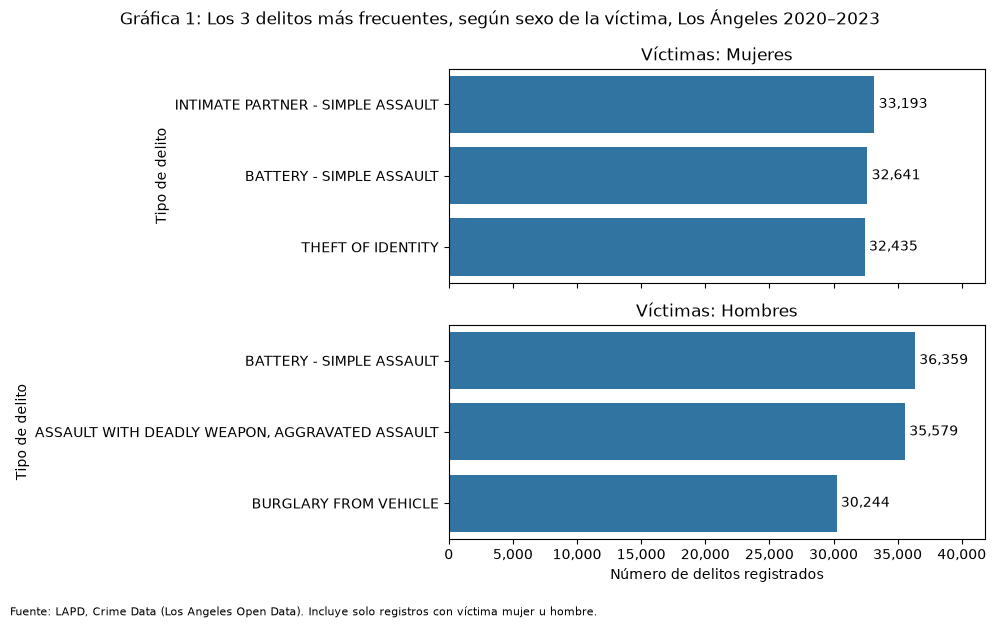

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Panel superior: mujeres
sns.barplot(data=df_muj, x="n_delitos", y="delito", ax=axes[0])
axes[0].set_title("Víctimas: Mujeres")
axes[0].set_ylabel("Tipo de delito")
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}", padding=3)

# Panel inferior: hombres
sns.barplot(data=df_hom, x="n_delitos", y="delito", ax=axes[1])
axes[1].set_title("Víctimas: Hombres")
axes[1].set_ylabel("Tipo de delito")
axes[1].set_xlabel("Número de delitos registrados")
axes[1].bar_label(axes[1].containers[0], fmt="{:,.0f}", padding=3)

# Eje X: separador de miles y espacio extra para las cifras
limite = max(df_muj["n_delitos"].max(), df_hom["n_delitos"].max()) * 1.15
axes[1].set_xlim(0, limite)
axes[1].xaxis.set_major_formatter("{x:,.0f}")

fig.suptitle("Gráfica 1: Los 3 delitos más frecuentes, según sexo de la víctima, Los Ángeles 2020–2023")
fig.text(0.01, -0.03, "Fuente: LAPD, Crime Data (Los Angeles Open Data). "
                     "Incluye solo registros con víctima mujer u hombre.", fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_01.png", dpi=160, bbox_inches="tight")
plt.show()

### Interpretación de gráfica 1:

En las mujeres, el delito más común durante el periodo 2020-2023 fue lesión simple por parte de la pareja íntima (33,193 casos), seguido de la lesión física simple (32,641) y el robo de identidad (32,435). 

En los hombres, el delito más común durante el periodo 2020-2023 fue la lesión física simple (36,359), la lesión agravada con arma mortal (35,579) y el robo al interior de vehículos (32,344). 

Así, a diferencia de los hombres, los registros muestran que las mujeres suelen ser más víctimas de violencia de pareja, mientras que los incidentes delictivos de hombres no presentan un contexto de violencia asociada a la pareja.

Igualmente, es importante enfatizar que los registros representan aquellos  incidentes conocidos por LAPD. De manera que, para dimensionar y cuantificar de manera más precisa la probabilidad de victimización, según sexo y tipo de delito, se requiere complementar el análisis con encuestas de victimización locales y encuestas de violencia de género. 

#### Pregunta complementaria 1: ¿Cuál fue la evolución temporal por año para los principales delitos?

- *Unidad de análisis:*\
Delitos registrados, según sexo de la víctima y año de ocurrencia

- *Universo:*\
683,121 registros con víctima mujer (F) u hombre (M) ocurridos entre 2020 y 2023

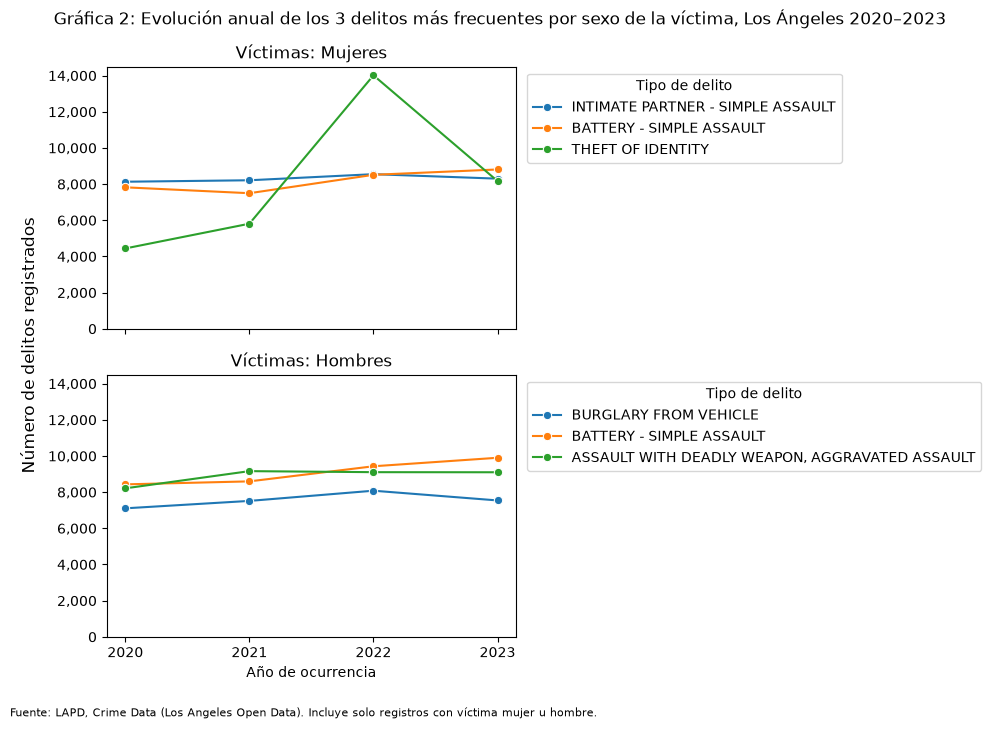

In [5]:
# Datos: solo los 3 principales delitos de cada sexo (identificados en la pregunta 1)
anio_muj = del_sexo_anio[(del_sexo_anio["sexo_vic"] == "F") &
                         (del_sexo_anio["delito"].isin(df_muj["delito"]))]
anio_hom = del_sexo_anio[(del_sexo_anio["sexo_vic"] == "M") &
                         (del_sexo_anio["delito"].isin(df_hom["delito"]))]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, sharey=True)

# Panel mujeres
sns.lineplot(data=anio_muj, x="anio", y="n_delitos", hue="delito",
             marker="o", errorbar=None, ax=axes[0])
axes[0].set_title("Víctimas: Mujeres")
axes[0].set_ylabel("")
sns.move_legend(axes[0], "upper left", bbox_to_anchor=(1.01, 1), title="Tipo de delito")

# Panel hombres
sns.lineplot(data=anio_hom, x="anio", y="n_delitos", hue="delito",
             marker="o", errorbar=None, ax=axes[1])
axes[1].set_title("Víctimas: Hombres")
axes[1].set_xlabel("Año de ocurrencia")
axes[1].set_ylabel("")
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1.01, 1), title="Tipo de delito")

# Ejes: un tick por año, separador de miles y eje Y desde cero
axes[1].set_xticks(sorted(del_sexo_anio["anio"].unique()))
axes[1].yaxis.set_major_formatter("{x:,.0f}")
axes[1].set_ylim(bottom=0)

fig.suptitle("Gráfica 2: Evolución anual de los 3 delitos más frecuentes por sexo de la víctima, Los Ángeles 2020–2023")
fig.supylabel("Número de delitos registrados")
fig.text(0.01, -0.03, "Fuente: LAPD, Crime Data (Los Angeles Open Data). "
                     "Incluye solo registros con víctima mujer u hombre.", fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_02.png", dpi=160, bbox_inches="tight")
plt.show()

#### Interpretación de la gráfica 2

Esta gráfica ofrece tres hallazgos importantes:
- Primero, para los delitos reportados en los que la víctima fue mujer, tanto lesión simple como lesión por pareja íntima se mantienen relativamente estables en el periodo analizado. Sin embargo, destaca que el delito de robo de identidad tuvo un crecimiento atípico en su reporte para el año 2022, mientras que para 2023, llega a los niveles de los otros dos tipos de delitos.

- Segundo, para los delitos reportados en los que la víctima fue hombre, los tres principales delitos se mantuvieron relativamente estables; sin embargo, estos cuatro años permiten apreciar un ligero aumento sostenido en lesiones simples, mientras que, para 2023, el número de delitos de robo de pertenencias del vehículo cae.

- Tercero, llama la atención que, a pesar de la pandemia ocasionada por COVID-19, para ambos sexos, los delitos ocurridos durante 2020 no muestran diferencias significativas en comparación con 2021.  


#### Pregunta complementaria 2: ¿En qué días de la semana y horas se cometió el principal tipo de delito, según el sexo de la víctima?

- *Unidad de análisis:*\
Delitos registrados, según día de la semana y hora de ocurrencia, para el delito principal de cada sexo

- *Universo:*\
683,121 registros con víctima mujer (F) u hombre (M) ocurridos entre 2020 y 2023

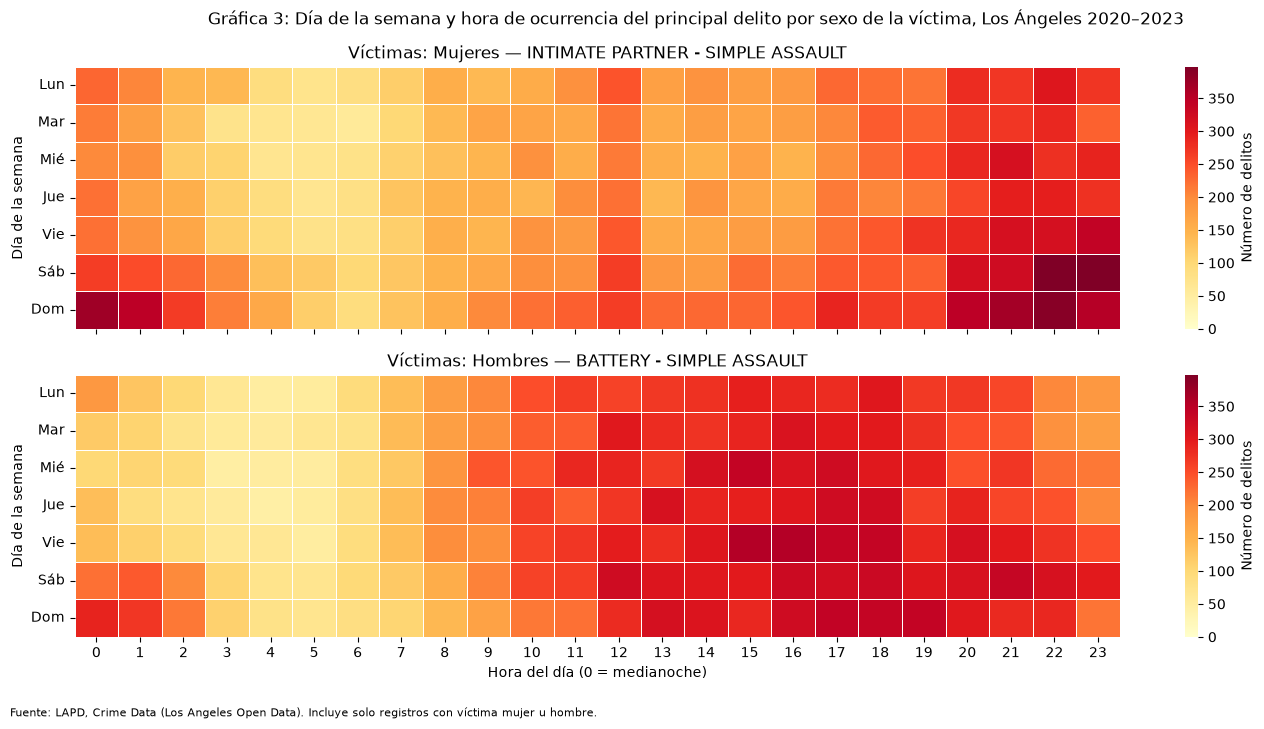

In [6]:
# Principal delito de cada sexo: primera fila del top 3 de la pregunta 1
delito_muj = df_muj["delito"].iloc[0]
delito_hom = df_hom["delito"].iloc[0]

# Datos de cada sexo, solo para su principal delito
dh_muj = del_dia_hora[(del_dia_hora["sexo_vic"] == "F") &
                      (del_dia_hora["delito"] == delito_muj)]
dh_hom = del_dia_hora[(del_dia_hora["sexo_vic"] == "M") &
                      (del_dia_hora["delito"] == delito_hom)]

# Tabla cruzada: días en filas, horas en columnas, conteos en las celdas
tabla_muj = dh_muj.pivot_table(index="diasem", columns="hora_occ",
                               values="n_delitos", aggfunc="sum", fill_value=0)
tabla_hom = dh_hom.pivot_table(index="diasem", columns="hora_occ",
                               values="n_delitos", aggfunc="sum", fill_value=0)

# Nombres de los días (diasem: 1 = lunes ... 7 = domingo)
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
tabla_muj.index = dias
tabla_hom.index = dias

# Misma escala de color en ambos paneles
vmax = max(tabla_muj.max().max(), tabla_hom.max().max())

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Panel superior: mujeres
sns.heatmap(tabla_muj, cmap="YlOrRd", vmin=0, vmax=vmax, linewidths=0.5,
            cbar_kws={"label": "Número de delitos"}, ax=axes[0])
axes[0].set_title(f"Víctimas: Mujeres — {delito_muj}")
axes[0].set_xlabel("")
axes[0].set_ylabel("Día de la semana")
axes[0].tick_params(axis="y", rotation=0)

# Panel inferior: hombres
sns.heatmap(tabla_hom, cmap="YlOrRd", vmin=0, vmax=vmax, linewidths=0.5,
            cbar_kws={"label": "Número de delitos"}, ax=axes[1])
axes[1].set_title(f"Víctimas: Hombres — {delito_hom}")
axes[1].set_xlabel("Hora del día (0 = medianoche)")
axes[1].set_ylabel("Día de la semana")
axes[1].tick_params(axis="y", rotation=0)

fig.suptitle("Gráfica 3: Día de la semana y hora de ocurrencia del principal delito por sexo de la víctima, Los Ángeles 2020–2023")
fig.text(0.01, -0.03, "Fuente: LAPD, Crime Data (Los Angeles Open Data). "
                     "Incluye solo registros con víctima mujer u hombre.", fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_03.png", dpi=160, bbox_inches="tight")
plt.show()

#### Interpretación de la gráfica 3

- Para el caso de delitos en los que la víctima fue mujer, la gráfica muestra un patrón muy claro: las lesiones simples relacionadas con la pareja íntima tienen mayor frecuencia en los fines de semana, particularmente en altas horas de la noche (entre las 22 y 01 horas). 

- Para el caso de delitos en los que la víctima fue hombre, la gráfica muestra un patrón más disperso: las lesiones simples ocurrieron con mayor frecuencia de miércoles a domingo entre las 14 y 18 horas del día. 

### Pregunta 2: Los 3 delitos más frecuentes por sexo de la víctima ¿ocurren de manera homogénea entre las 21 áreas geográficas o se concentran en áreas específicas?

- *Unidad de análisis:*\
Delitos registrados, según área de ocurrencia y sexo de la víctima

- *Universo:*\
683,121 registros con víctima mujer (F) u hombre (M) entre 2020 y 2023

In [7]:
# Primero calculamos el porcentaje acumulado para distinguir qué áreas 
# concentran más de 50% de los delitos reportados

# Sumar todos los delitos por área y sexo
area_sexo = (del_area
             .groupby(["sexo_vic", "nom_area"], as_index=False)["n_delitos"]
             .sum())

# Después creamos una función que ordena las áreas de un sexo y marca las que concentran el 50 %
def areas_50(df, sexo):
    datos = (df[df["sexo_vic"] == sexo]
             .sort_values("n_delitos", ascending=False)
             .reset_index(drop=True))
    datos["pct"] = 100 * datos["n_delitos"] / datos["n_delitos"].sum()
    datos["pct_acum"] = datos["pct"].cumsum()
    # Un área entra al grupo si el acumulado ANTES de ella era menor a 50
    datos["grupo_50"] = (datos["pct_acum"] - datos["pct"]) < 50
    datos["grupo"] = datos["grupo_50"].map({True: "Concentran el 50 %", False: "Resto"})
    return datos

areas_muj = areas_50(area_sexo, "F")
areas_hom = areas_50(area_sexo, "M")

# Imprime las primeras filas de cada sexo
print(areas_muj[["nom_area", "pct", "pct_acum", "grupo_50"]].head(10))
print(areas_hom[["nom_area", "pct", "pct_acum", "grupo_50"]].head(10))


      nom_area       pct   pct_acum  grupo_50
0  77th Street  7.554730   7.554730      True
1    Southwest  6.283513  13.838243      True
2    Southeast  6.212494  20.050737      True
3      Central  5.907327  25.958064      True
4      Pacific  5.192791  31.150856      True
5      Olympic  4.919878  36.070734      True
6       Newton  4.907473  40.978207      True
7    Hollywood  4.880802  45.859009      True
8  N Hollywood  4.678288  50.537298      True
9     Wilshire  4.549275  55.086572     False
      nom_area       pct   pct_acum  grupo_50
0      Central  8.268131   8.268131      True
1  N Hollywood  6.230834  14.498966      True
2      Pacific  5.759217  20.258183      True
3    Hollywood  5.471423  25.729606      True
4      Topanga  5.270133  30.999739      True
5  West Valley  5.241853  36.241592      True
6       Newton  5.022541  41.264133      True
7  77th Street  4.974853  46.238986      True
8     Wilshire  4.883080  51.122066      True
9      West LA  4.776890  55.89895

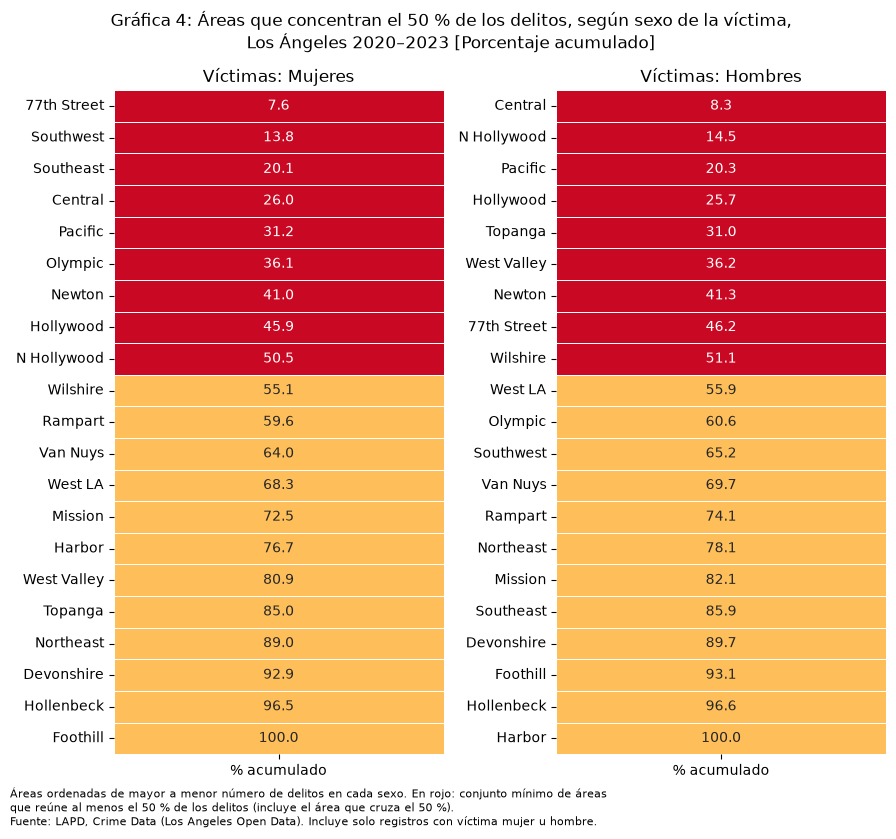

In [8]:
# Dos colores de la paleta del mapa de calor: 0 = resto, 1 = concentran el 50 %
colores = sns.color_palette("YlOrRd", 5)
colores_grupo = [colores[1], colores[4]]

# Número de áreas en el grupo del 50 % (para los títulos)
n_muj = areas_muj["grupo_50"].sum()
n_hom = areas_hom["grupo_50"].sum()

fig, axes = plt.subplots(1, 2, figsize=(9, 8))

# Panel izquierdo: mujeres
sns.heatmap(areas_muj.set_index("nom_area")[["grupo_50"]].astype(int),
            cmap=colores_grupo, vmin=0, vmax=1, cbar=False,
            annot=areas_muj[["pct_acum"]].to_numpy(), fmt=".1f",
            linewidths=0.5, linecolor="white",
            xticklabels=["% acumulado"], ax=axes[0])
axes[0].set_title(f"Víctimas: Mujeres")
axes[0].set_ylabel("")
axes[0].tick_params(axis="y", rotation=0)

# Panel derecho: hombres
sns.heatmap(areas_hom.set_index("nom_area")[["grupo_50"]].astype(int),
            cmap=colores_grupo, vmin=0, vmax=1, cbar=False,
            annot=areas_hom[["pct_acum"]].to_numpy(), fmt=".1f",
            linewidths=0.5, linecolor="white",
            xticklabels=["% acumulado"], ax=axes[1])
axes[1].set_title(f"Víctimas: Hombres")
axes[1].set_ylabel("")
axes[1].tick_params(axis="y", rotation=0)

fig.suptitle("Gráfica 4: Áreas que concentran el 50 % de los delitos, según sexo de la víctima,\nLos Ángeles 2020–2023 [Porcentaje acumulado]")
fig.text(0.01, -0.04,
         "Áreas ordenadas de mayor a menor número de delitos en cada sexo. En rojo: conjunto mínimo de áreas\n"
         "que reúne al menos el 50 % de los delitos (incluye el área que cruza el 50 %).\n"
         "Fuente: LAPD, Crime Data (Los Angeles Open Data). Incluye solo registros con víctima mujer u hombre.",
         fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_04.png", dpi=160, bbox_inches="tight")
plt.show()

#### Interpretación de gráfica 4:

 - El gráfico muestra que 9 de 21 áreas geográficas concentran 50% o más de los delitos reportados. Esto aplica tanto para delitos en los que las víctimas fueron mujeres, como para las víctimas hombres. 
 - Igualmente, el gráfico muestra que las áreas con alta concentración de incidentes delictivos coinciden en 6 de las 9: Central, 77th Street, Pacific, Newton, Hollywood, y N Hollywood.
 - Las áreas de Southwest, Southeast, y Olympic son las otras tres zonas con alta concentración de incidentes delictivos solamente para delitos con víctimas mujeres. 
 - Las áreas de Topanga, West Valley, y Wilshire son las otras tres zonas con alta concentración de incidentes delictivos solamente para delitos con víctimas hombres. 


 - Entre las `limitaciones` de este gráfico se encuentran: 
 - El gráfico de concentración no representa riesgo relativo (tasas), por lo que la concentración de delitos puede ser reflejo del contexto de las áreas donde ocurren, por ejemplo: que sean las áreas más pobladas o bien que sean aquellas que reciben mayor cantidad de personas, sea por trabajo, turismo u otros factores. 
 - Otra limitación de este gráfico tiene que ver con que solamente se están mostrando delitos para los cuales se registró el sexo de la víctima. Así, delitos como robo de vehículo no aparecen y podrían afectar el patrón identificado en este gráfico.
 - Por último, este ejercicio utilizó áreas administrativas que fueron delimitadas por LAPD. Esto conlleva el riesgo de identificar con precisión dónde se concentran los incidentes delictivos. Para ello, el ejercicio tendría que complementarse con un mapa de calor.  

#### Pregunta complementaria 3: ¿Qué áreas de la ciudad concentran el principal tipo de delito, según sexo de la víctima?

- *Unidad de análisis:*\
Principal delito registrado, según área de ocurrencia y sexo de la víctima

- *Universo:*\
683,121 registros con víctima mujer (F) u hombre (M) ocurridos entre 2020 y 2023

In [9]:
# Principal delito de cada sexo (delito_muj y delito_hom vienen de la pregunta 3)
area_del_muj = del_area[(del_area["sexo_vic"] == "F") & (del_area["delito"] == delito_muj)]
area_del_hom = del_area[(del_area["sexo_vic"] == "M") & (del_area["delito"] == delito_hom)]

# Misma función de la pregunta 4: ordena, calcula % y % acumulado, y marca el 50 %
areas_del_muj = areas_50(area_del_muj, "F")
areas_del_hom = areas_50(area_del_hom, "M")

# Verificación
print(areas_del_muj[["nom_area", "pct", "pct_acum", "grupo_50"]].head(10))
print(areas_del_hom[["nom_area", "pct", "pct_acum", "grupo_50"]].head(10))

      nom_area       pct   pct_acum  grupo_50
0  77th Street  9.230862   9.230862      True
1    Southeast  7.766698  16.997560      True
2    Southwest  6.447142  23.444702      True
3       Newton  6.176001  29.620703      True
4      Olympic  5.699997  35.320700      True
5      Mission  5.483084  40.803784      True
6      Rampart  5.323412  46.127195      True
7       Harbor  5.160727  51.287922      True
8      Central  4.660621  55.948543     False
9  N Hollywood  4.552165  60.500708     False
      nom_area        pct   pct_acum  grupo_50
0      Central  10.201051  10.201051      True
1    Hollywood   6.812619  17.013669      True
2      Olympic   6.193790  23.207459      True
3      Rampart   5.880250  29.087709      True
4       Newton   5.602464  34.690173      True
5    Southwest   5.379686  40.069859      True
6  77th Street   5.107401  45.177260      True
7  N Hollywood   4.821365  49.998625      True
8      Pacific   4.686598  54.685222      True
9      West LA   4.39506

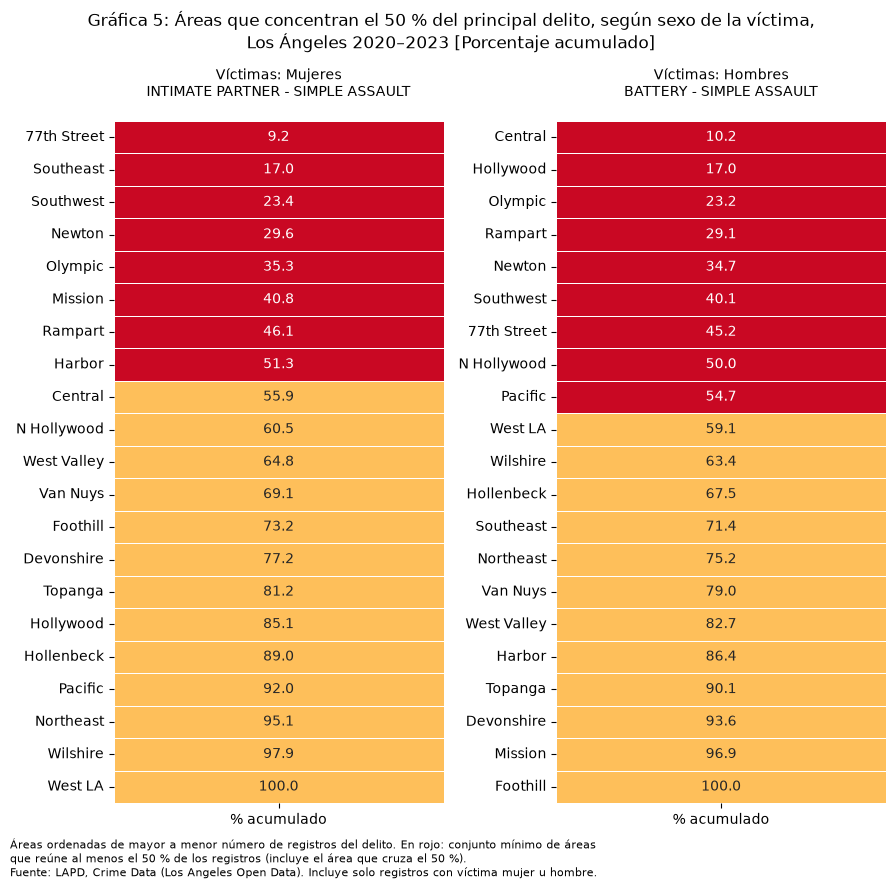

In [10]:
# Utilizamos los mismos colores de la pregunta 4
colores = sns.color_palette("YlOrRd", 5)
colores_grupo = [colores[1], colores[4]]

# Definimos el número de áreas en el grupo del 50 % para el principal delito
n_del_muj = areas_del_muj["grupo_50"].sum()
n_del_hom = areas_del_hom["grupo_50"].sum()

fig, axes = plt.subplots(1, 2, figsize=(9, 8.5))

# Panel mujeres
sns.heatmap(areas_del_muj.set_index("nom_area")[["grupo_50"]].astype(int),
            cmap=colores_grupo, vmin=0, vmax=1, cbar=False,
            annot=areas_del_muj[["pct_acum"]].to_numpy(), fmt=".1f",
            linewidths=0.5, linecolor="white",
            xticklabels=["% acumulado"], ax=axes[0])
axes[0].set_title(f"Víctimas: Mujeres\n{delito_muj}\n"
                  , fontsize=10)
axes[0].set_ylabel("")
axes[0].tick_params(axis="y", rotation=0)

# Panel hombres
sns.heatmap(areas_del_hom.set_index("nom_area")[["grupo_50"]].astype(int),
            cmap=colores_grupo, vmin=0, vmax=1, cbar=False,
            annot=areas_del_hom[["pct_acum"]].to_numpy(), fmt=".1f",
            linewidths=0.5, linecolor="white",
            xticklabels=["% acumulado"], ax=axes[1])
axes[1].set_title(f"Víctimas: Hombres\n{delito_hom}\n"
                  , fontsize=10)
axes[1].set_ylabel("")
axes[1].tick_params(axis="y", rotation=0)

fig.suptitle("Gráfica 5: Áreas que concentran el 50 % del principal delito, según sexo de la víctima,\n"
             "Los Ángeles 2020–2023 [Porcentaje acumulado]")
fig.text(0.01, -0.04,
         "Áreas ordenadas de mayor a menor número de registros del delito. En rojo: conjunto mínimo de áreas\n"
         "que reúne al menos el 50 % de los registros (incluye el área que cruza el 50 %).\n"
         "Fuente: LAPD, Crime Data (Los Angeles Open Data). Incluye solo registros con víctima mujer u hombre.",
         fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_05.png", dpi=160, bbox_inches="tight")
plt.show()

#### Interpretación de gráfica 5:

 - A diferencia del total de delitos, según área y sexo de la víctima, al especificar el principal tipo de sexo, se observan algunas diferencias importantes.

 - Para el delito de lesión simple en contexto de pareja íntima, con mujeres víctimas, destaca que más del 50% de estos incidentes ocurrió en 8 de 21 áreas, es decir, se encuentra más acotado. De hecho las zonas dos y tres se encuentran al sur de la ciudad. Como hipótesis, esto quizá se deba a que dichas áreas son más residenciales que las áreas centrales o al norte de la ciudad, pero requiere un análisis más detallado.

 - Para el delito de lesión simple, con hombres víctimas, la concentración de más del 50% concuerda con el patrón global: 9 de 21 zonas. Además, destaca que las áreas 'Central' y 'Hollywood' se caracterizan por su alta actividad comercial y nocturna. Este hallazgo se vincula con los días de la semana y horas de mayor ocurrencia de dicho delito.

 - Las lesiones, tanto para víctimas mujeres como hombres, comparten 5 áreas: 77th Street, Southwest, Newton, Olympic y Rampart. 
 
 - Solo dos áreas aparecen tanto en la concentración global como para estos tipos específicos de delitos: 77th Street y Newton. A reserva de indagar más sobre el contexto y rutinas de dichas áreas, este hallazgo puede servir para priorizar las políticas de prevención del delito.  

### Selección de hallazgos principales:

Tomando en consideración el sexo de la víctima, el principal tipo de delito, su contexto temporal, y las zonas, este ejercicio brinda algunos hallazgos que vale la pena subrayar: 

- `1`: Existen diferencias importantes en cuanto a la composición de delitos que afectan a mujeres y hombres. Mientras las mujeres son principalmente agravadas por lesiones en contexto de pareja íntima, los hombres suelen ser más víctimas de lesiones simples.

- `2:` Los delitos reportados sí se concentran en áreas específicas de la ciudad: 9 de 21. No obstante, el análisis  muestra que hay diferencias importantes al desagregar por tipo de delito y sexo de la víctima. Esto remite al contexto, rutinas y factores de riesgo y oportunidad criminal de cada zona. 

- `3:` Sin importar el sexo de la víctima y el tipo de delito, 77th Street y Newton fueron las áreas que aparecieron de manera consistente en el listado de áreas con alta concentración de incidentes criminales. 